# LIAR2 dataset analysis

This notebook loads the LIAR2 benchmark from Hugging Face and explores its official train, validation, and test splits. It focuses on the dataset's labeled fact-checking claims; it does not fetch or display a feed of new articles.

To run it in Google Colab, upload this notebook with **File > Upload notebook**. The first code cell installs the required packages.

In [57]:
%pip install -q datasets pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [58]:
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset

DATASET_ID = "chengxuphd/liar2"
LABEL_NAMES = ["pants-fire", "false", "barely-true", "half-true", "mostly-true", "true"]

dataset = load_dataset(DATASET_ID)
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['id', 'label', 'statement', 'date', 'subject', 'speaker', 'speaker_description', 'state_info', 'true_counts', 'mostly_true_counts', 'half_true_counts', 'mostly_false_counts', 'false_counts', 'pants_on_fire_counts', 'context', 'justification'],
        num_rows: 18369
    })
    validation: Dataset({
        features: ['id', 'label', 'statement', 'date', 'subject', 'speaker', 'speaker_description', 'state_info', 'true_counts', 'mostly_true_counts', 'half_true_counts', 'mostly_false_counts', 'false_counts', 'pants_on_fire_counts', 'context', 'justification'],
        num_rows: 2297
    })
    test: Dataset({
        features: ['id', 'label', 'statement', 'date', 'subject', 'speaker', 'speaker_description', 'state_info', 'true_counts', 'mostly_true_counts', 'half_true_counts', 'mostly_false_counts', 'false_counts', 'pants_on_fire_counts', 'context', 'justification'],
        num_rows: 2296
    })
})


In [59]:
def to_dataframe(split_name):
    frame = dataset[split_name].to_pandas()
    if "label" not in frame.columns:
        raise ValueError(f"The {split_name!r} split has no 'label' column.")

    labels = frame["label"]
    if pd.api.types.is_integer_dtype(labels):
        frame["label_name"] = labels.map(dict(enumerate(LABEL_NAMES)))
        if frame["label_name"].isna().any():
            raise ValueError(f"Unexpected numeric label in the {split_name!r} split.")
    else:
        frame["label_name"] = labels.astype(str).str.lower().str.replace("_", "-", regex=False)
    frame["split"] = split_name
    return frame

split_names = list(dataset.keys())
frames = {name: to_dataframe(name) for name in split_names}
liar2 = pd.concat(frames.values(), ignore_index=True)

split_summary = pd.DataFrame(
    [{"split": name, "rows": len(frame), "columns": len(frame.columns)}
     for name, frame in frames.items()]
)
display(split_summary)
print(f"Total records: {len(liar2):,}")

,split,rows,columns
0,train,18369,18
1,validation,2297,18
2,test,2296,18


Total records: 22,962


## Label distribution

label_name,pants-fire,false,barely-true,half-true,mostly-true,true
split,,,,,,
test,303,660,360,371,343,259
train,2425,5284,2882,2967,2743,2068
validation,303,661,361,371,343,258


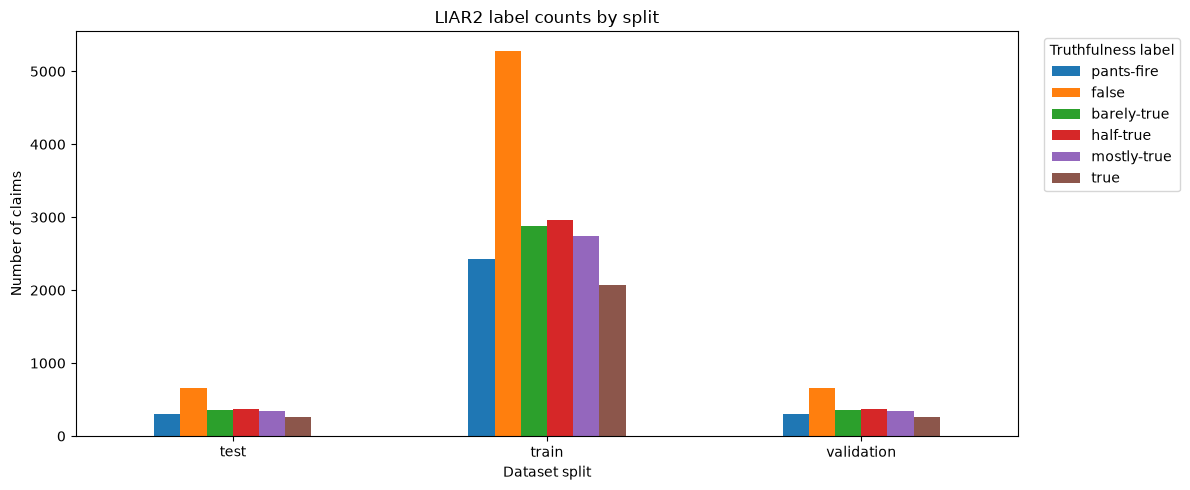

In [60]:
label_counts = (
    liar2.groupby(["split", "label_name"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=LABEL_NAMES, fill_value=0)
)
display(label_counts)

label_counts.plot(kind="bar", figsize=(12, 5), rot=0)
plt.title("LIAR2 label counts by split")
plt.xlabel("Dataset split")
plt.ylabel("Number of claims")
plt.legend(title="Truthfulness label", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Data quality and statement length

,missing_values,missing_percent
state_info,5641,24.57
subject,207,0.90
context,154,0.67
speaker_description,10,0.04
label,0,0.00
id,0,0.00
speaker,0,0.00
date,0,0.00
true_counts,0,0.00
statement,0,0.00


Duplicate IDs: 0


,count,mean,median,min,max
label_name,,,,,
pants-fire,3031,16.0,14.0,2,62
false,6605,16.5,15.0,2,73
barely-true,3603,18.5,17.0,3,62
half-true,3709,19.3,18.0,3,79
mostly-true,3429,18.6,17.0,3,66
true,2585,18.1,17.0,4,66


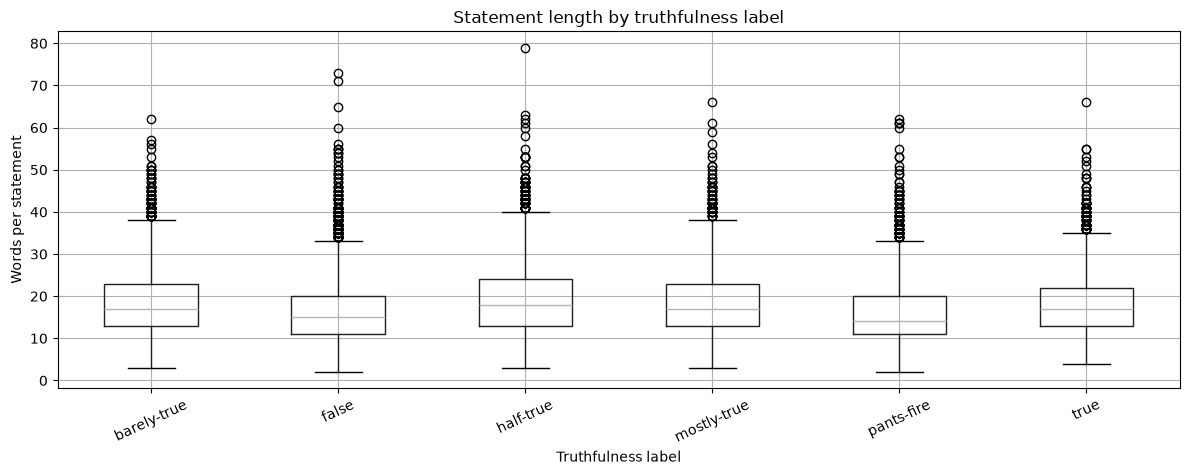

In [61]:
quality_summary = pd.DataFrame({
    "missing_values": liar2.isna().sum(),
    "missing_percent": (liar2.isna().mean() * 100).round(2),
})
display(quality_summary.sort_values("missing_values", ascending=False).head(15))

if "id" in liar2.columns:
    print(f"Duplicate IDs: {liar2['id'].duplicated().sum():,}")

if "statement" not in liar2.columns:
    raise ValueError("The dataset has no 'statement' column.")

liar2["statement_word_count"] = liar2["statement"].fillna("").astype(str).str.split().str.len()
length_summary = liar2.groupby("label_name")["statement_word_count"].agg(
    ["count", "mean", "median", "min", "max"]
).reindex(LABEL_NAMES).round(1)
display(length_summary)

liar2.boxplot(column="statement_word_count", by="label_name", figsize=(12, 5), rot=25)
plt.title("Statement length by truthfulness label")
plt.suptitle("")
plt.xlabel("Truthfulness label")
plt.ylabel("Words per statement")
plt.tight_layout()
plt.show()

## Most common subjects

,claim_count
subject,
candidate biography,1012
state budget,1035
crime,1101
federal budget,1130
jobs,1147
public health,1183
immigration,1222
education,1319
punditfact,1320


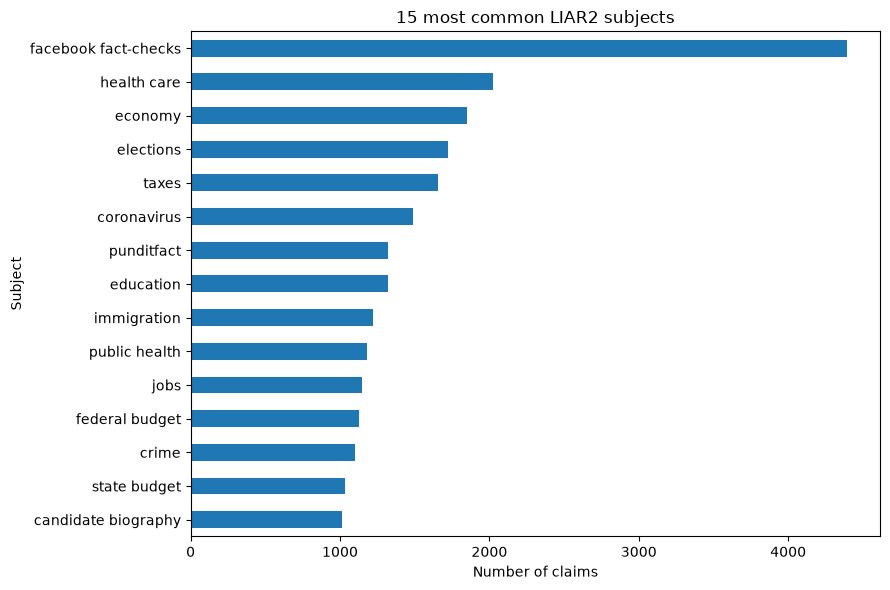

In [62]:
if "subject" not in liar2.columns:
    raise ValueError("The dataset has no 'subject' column.")

subjects = (
    liar2["subject"]
    .dropna()
    .astype(str)
    .str.split(";")
    .explode()
    .str.strip()
)
top_subjects = subjects[subjects.ne("")].value_counts().head(15).sort_values()
display(top_subjects.rename("claim_count").to_frame())

top_subjects.plot(kind="barh", figsize=(9, 6))
plt.title("15 most common LIAR2 subjects")
plt.xlabel("Number of claims")
plt.ylabel("Subject")
plt.tight_layout()
plt.show()

## Explore claims

Change `selected_split` or `selected_label` to inspect a sample of records. This displays fact-checked claims from LIAR2, not a stream of newly published articles.

In [63]:
selected_split = "train"  # Options depend on the dataset: train, validation, test
selected_label = "all"  # Choose a label from LABEL_NAMES or "all"
sample_size = 10

if selected_split not in frames:
    raise ValueError(f"Unknown split {selected_split!r}. Available splits: {list(frames)}")
claims = frames[selected_split]
if selected_label != "all":
    if selected_label not in LABEL_NAMES:
        raise ValueError(f"Unknown label {selected_label!r}. Choose from {LABEL_NAMES} or 'all'.")
    claims = claims[claims["label_name"] == selected_label]

display(claims.head(sample_size))

,id,label,statement,date,subject,speaker,speaker_description,state_info,true_counts,mostly_true_counts,half_true_counts,mostly_false_counts,false_counts,pants_on_fire_counts,context,justification,label_name,split
0,13847,5,"90 percent of Americans ""support universal bac...","October 2, 2017",government regulation;polls and public opinion...,chris abele,"Chris Abele is Milwaukee County Executive, a p...",wisconsin,1,4,5,3,5,2,a tweet,"""Universal"" is the term for background checks ...",true,train
1,13411,1,Last year was one of the deadliest years ever ...,"May 19, 2017",after the fact;congress;criminal justice;histo...,thom tillis,Thom Tillis is a Republican who serves as U.S....,north carolina,0,2,7,3,2,0,a press release supporting the Back The Blue A...,"Sen. Thom Tillis, a North Carolina Republican,...",false,train
2,10882,0,"Bernie Sanders's plan is ""to raise your taxes ...","October 28, 2015",taxes,chris christie,"Chris Christie announced June 6, 2023 that he ...",national,21,20,27,11,17,8,"Boulder, Colo","Christie said that Sanders’s plan is ""to raise...",pants-fire,train
3,20697,4,Voter ID is supported by an overwhelming major...,"December 8, 2021",voter id laws,lee zeldin,Lee Zeldin is a Republican representing New Yo...,new york,1,2,0,0,0,0,a Tweet,Zeldin claimed voter identification requiremen...,mostly-true,train
4,6095,2,"Says Barack Obama ""robbed Medicare (of) $716 b...","August 12, 2012",federal budget;history;medicare;retirement,mitt romney,Mitt Romney is a U.S. senator from Utah. He ra...,national,31,33,58,35,32,19,"an interview on ""60 Minutes""","Romney said, ""There's only one president that ...",barely-true,train
5,19520,0,"Video says COVID-19 vaccines are ""weapons of m...","March 28, 2021",facebook fact-checks;coronavirus,facebook posts,Posters on Facebook and other social media net...,NaN,24,50,108,245,1410,570,a video on Facebook,A video circulating on Facebook claims COVID-1...,pants-fire,train
6,5561,2,Says Jeff Reardon cut elementary school music ...,"May 8, 2012",education;message machine 2012;voting record,mike schaufler,"Rep. Mike Schaufler, D-Portland, represents Or...",oregon,0,0,0,1,0,0,campaign mailer,"If ""Reardon’s cuts"" shortchanged children, the...",barely-true,train
7,15600,3,One in three women is sexually assaulted on th...,"January 19, 2019",immigration;corrections and updates;homeland s...,donald trump,Donald Trump is the former president of the Un...,national,36,85,120,194,360,179,a speech,"Trump said, ""One in three women is sexually as...",half-true,train
8,17285,1,It's actually the safest time to fly.,"March 13, 2020",public health;punditfact;coronavirus,ainsley earhardt,Ainsley Earhardt is a co-host of Fox News Chan...,NaN,0,0,0,0,2,0,the Fox & Friends show,"Earhardt said that ""it's actually the safest t...",false,train
9,15300,1,We know dangerous criminals can slip through i...,"October 24, 2018",immigration,national republican senatorial committee,The National Republican Senatorial Committee h...,national,1,3,11,18,14,7,a digital ad,"NRSC said, ""We know dangerous criminals can sl...",false,train
